# 1 · Data layer: one parameter table for every human gene

Every number in the model enters through `humancell.data`. For each of the 20,162 protein-coding genes it
assembles abundance, turnover and location from public measurements, records where each value came from,
and derives rate constants so that the measured state is a steady state of the model:

* `k_tx = m (d_m + μ)` transcripts per hour, `k_tl = p (d_p + μ) / m` proteins per mRNA per hour.

| Quantity | Source | Fallback |
|---|---|---|
| mRNA copies | Human Protein Atlas RNA-seq (HeLa), scaled to 4×10⁵ mRNA/cell | <1 TPM = not expressed |
| protein copies | PaxDB HeLa deep proteome (Müller 2020) | integrated human proteome, then mRNA regression |
| half-lives | Schwanhäusser 2011 (mouse orthologue) + 35 curated short-lived regulators | median (9 h mRNA, 46 h protein) |
| compartment | HPA imaging | UniProt annotation |
| length, mass | UniProt | median |

In [1]:
import sys, pathlib; sys.path.insert(0, str(pathlib.Path.cwd().parent))
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from humancell import data, plotting as P; P.style()

g = data.build_gene_table("HeLa")
print(f"{len(g):,} genes, {int(g.expressed.sum()):,} expressed in HeLa")
g[["symbol", "mrna", "protein", "t_half_mrna", "t_half_prot", "compartment", "k_tx", "k_tl"]].sort_values("protein", ascending=False).head(8).round(2)

20,162 genes, 12,665 expressed in HeLa


,symbol,mrna,protein,t_half_mrna,t_half_prot,compartment,k_tx,k_tl
ensembl,,,,,,,,
ENSG00000212907,MT-ND4L,8718.63,83691591.24,9.00,46.00,mitochondria,946.17,447.08
ENSG00000205542,TMSB4X,2850.49,61202108.70,9.00,46.00,cytosol,309.34,1000.00
ENSG00000111640,GAPDH,2229.56,47870184.38,9.00,46.00,cytosol,241.96,1000.00
ENSG00000034510,TMSB10,1562.58,31178362.68,24.06,57.69,cytosol,94.25,868.39
ENSG00000142168,SOD1,822.12,23296526.06,14.86,183.25,nucleus,64.25,1000.00
ENSG00000156508,EEF1A1,2026.78,21399390.63,17.50,126.33,cytosol,144.13,390.59
ENSG00000084207,GSTP1,687.82,20200938.09,21.21,272.68,cytosol,44.15,1000.00
ENSG00000108518,PFN1,1146.15,19587644.86,16.04,115.73,cytosol,85.64,640.81


## Provenance: measured versus inferred
The model is only as good as these inputs, so the split is stated up front.

In [2]:
def share(col, label):
    s = g.loc[g.expressed, col].str.replace(r" \(.*\)", "", regex=True).value_counts()
    return pd.DataFrame({"quantity": label, "source": s.index, "genes": s.values, "share": (s.values / s.sum()).round(3)})
prov = pd.concat([share("mrna_src", "mRNA abundance"), share("protein_src", "protein abundance"),
                  share("t_half_prot_src", "protein half-life"), share("t_half_mrna_src", "mRNA half-life"),
                  share("compartment_src", "compartment")])
prov.set_index(["quantity", "source"])

genes  share
quantity          source                             
mRNA abundance    HPA RNA-seq            11864  0.937
                  imputed from proteome    801  0.063
protein abundance PaxDB HeLa              9378  0.740
                  PaxDB integrated        3019  0.238
                  mRNA-regression          268  0.021
protein half-life default median          8511  0.672
                  Schwanhaeusser 2011     4120  0.325
                  literature                34  0.003
mRNA half-life    default median          8708  0.688
                  Schwanhaeusser 2011     3923  0.310
                  literature                34  0.003
compartment       HPA                    10262  0.810
                  UniProt                 2052  0.162
                  default                  351  0.028

Abundances are measured for most expressed genes. **Half-lives are the weak point**: about two thirds of
expressed genes fall back to the median, so the timing of responses for those genes is approximate.

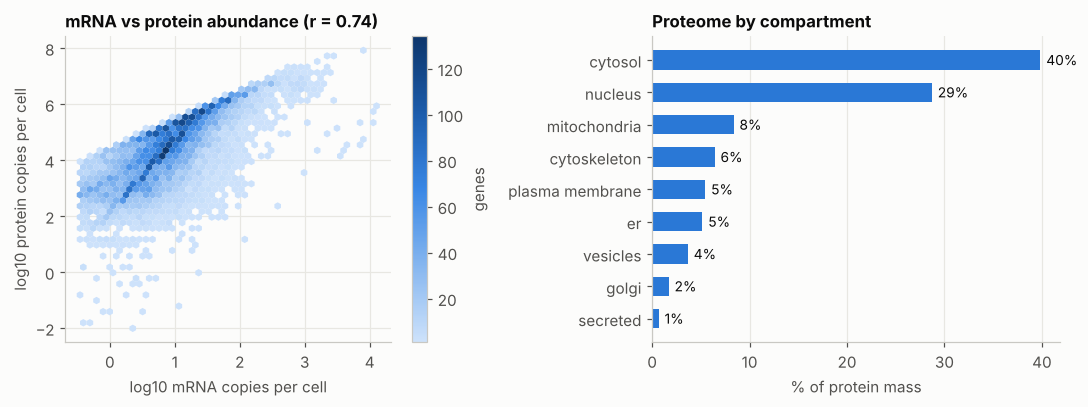

In [3]:
e = g[g.expressed]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
ax = axes[0]
hb = ax.hexbin(np.log10(e.mrna), np.log10(e.protein), gridsize=45, cmap=plt.matplotlib.colors.LinearSegmentedColormap.from_list("s", P.SEQUENTIAL), mincnt=1, linewidths=0)
r = np.corrcoef(np.log10(e.mrna), np.log10(e.protein))[0, 1]
ax.set_xlabel("log10 mRNA copies per cell"); ax.set_ylabel("log10 protein copies per cell")
ax.set_title(f"mRNA vs protein abundance (r = {r:.2f})"); fig.colorbar(hb, ax=ax, label="genes")
ax = axes[1]
frac = (e.protein * e.mass).groupby(e.compartment).sum().sort_values() / (e.protein * e.mass).sum()
ax.barh(frac.index.str.replace("_", " "), frac.values * 100, color=P.SERIES[0], height=0.6)
for y, v in enumerate(frac.values * 100):
    ax.text(v + 0.6, y, f"{v:.0f}%", va="center", fontsize=9)
ax.grid(axis="y", visible=False); ax.set_xlabel("% of protein mass"); ax.set_title("Proteome by compartment")
plt.tight_layout(); plt.show()

## Do the numbers add up to a real cell?
Independent physical checks; none of these were fitted.

In [4]:
mu = np.log(2) / data.PHYS["doubling_h"]
rp = e[e.symbol.str.match(r"^RP[LS]\d+[AXY]?$")]
ribosomes = rp.protein.median()
aa_per_s = (e.protein * (e.d_p + mu) * e.length).sum() / 3600
checks = pd.DataFrame([
    ("total protein", f"{(e.protein * e.mass).sum() / 6.022e23 * 1e12:.0f} pg", "150–300 pg (HeLa)"),
    ("protein molecules", f"{e.protein.sum():.2e}", "2–4 ×10⁹"),
    ("mRNA molecules", f"{e.mrna.sum():.2e}", "2–8 ×10⁵"),
    ("ribosomes (median r-protein copies)", f"{ribosomes:.2e}", "3–10 ×10⁶"),
    ("amino acids polymerised per second", f"{aa_per_s:.2e}", "—"),
    ("implied elongation rate per ribosome", f"{aa_per_s / ribosomes:.1f} aa/s", "≈5–6 aa/s measured"),
    ("median translation rate", f"{e.k_tl.median():.0f} proteins/mRNA/h", "≈140 (Schwanhäusser 2011)"),
    ("transcription events per hour", f"{e.k_tx.sum():.2e}", "—"),
], columns=["quantity", "model", "literature"]).set_index("quantity")
checks

,model,literature
quantity,,
total protein,270 pg,150–300 pg (HeLa)
protein molecules,3.88e+09,2–4 ×10⁹
mRNA molecules,4.44e+05,2–8 ×10⁵
ribosomes (median r-protein copies),4.71e+06,3–10 ×10⁶
amino acids polymerised per second,1.83e+07,—
implied elongation rate per ribosome,3.9 aa/s,≈5–6 aa/s measured
median translation rate,166 proteins/mRNA/h,≈140 (Schwanhäusser 2011)
transcription events per hour,4.52e+04,—


The implied ribosome elongation rate lands in the measured range without being tuned, which means the
abundance, turnover and growth data are mutually consistent at the scale of the whole cell.

**Reconciliation rule.** Where abundance × turnover would require more than 1,000 proteins per mRNA per hour
(a physical bound set by ribosome spacing), the transcript count is raised for stable proteins or the protein
count lowered for short-lived regulators. The affected genes are labelled in `mrna_src` / `protein_src`.

In [5]:
nets = {"signalling interactions (OmniPath, signed, directed)": len(data.signaling_edges()),
        "TF → target interactions (CollecTRI)": len(data.regulon_edges()),
        "protein complexes (OmniPath, ≥2 sources)": len(data.complexes())}
pd.Series(nets, name="count").to_frame()

,count
"signalling interactions (OmniPath, signed, directed)",14448
TF → target interactions (CollecTRI),43054
"protein complexes (OmniPath, ≥2 sources)",10482
